# Shazam (Part 1)

A Running exercise to replicate the Shazam algorithm.

## Goals

- Practicing with pandas `DataFrames`
- Building intuition for distances
- Experimenting with evaluation strategies

## Setup

Run the following 2 cells to import all necessary libraries and helpers for this homework

In [1]:
!mkdir -p data/audio
!wget -q https://github.com/PSAM-5020-2026F-A/5020-utils/raw/refs/heads/main/datasets/audio/hood-internet.tar.gz
!tar -xzf ./hood-internet.tar.gz -C ./data/audio/ && rm -rf hood-internet.tar.gz*

In [2]:
import librosa
import matplotlib.pyplot as plt
import pandas as pd

from IPython.display import Audio
from os import listdir

## Shazam !

Yep. Let's replicate the Shazam algorithm. It's the same type of classification task we've been looking at, but instead of classifying a piece of audio into one of $3$ classes, the algorithm has to pick which of the millions of songs the piece of audio most likely came from.

We've created some simple classification models by manually extracting features that we think are important for the differentiation of our classes. This is ok if we're only dealing with a few classes, but it doesn't scale. If we had to classify audio into hundreds, or thousands, of classes, looking at graphs of relative frequencies and loudness for all classes becomes intractable.

We need something a little more systematic. Something that automatically extracts meaningful numeric information from audio, independent of the type of audio.

Let's look at the frequency domain again, and use the librosa library to help us extract consistent frequency information from audio files.

## Librosa Feature Extraction

Librosa is useful because it has many feature extraction functions to actually get meaningful frequency information from our audios files:

[Librosa Reference and Documentation](https://librosa.org/doc/latest/feature.html)

### Some example functions

- `librosa.feature.spectral_centroid` (extracts average frequency)
- `librosa.feature.spectral_bandwidth` (extracts frequency range)
- `librosa.feature.spectral_rolloff(roll_percent=0.01)` (extarcts smallest frequency)
- `librosa.feature.spectral_rolloff(roll_percent=0.99)` (extracts largest frequency)

Let's load a song and see what running these looks like:

### ❗️❗️ WARNING ❗️❗️

The songs we'll be using are from mixtapes by [The Hood Internet](https://www.thehoodinternet.com/). They were part of a wave of _mashup_ producers in the early $2\text{,}000\text{s}$ that mixed _classic_ american indie, pop and rap music from other time periods.

We're using their mixtapes here mostly because: they're available freely on the internet, they encompass a good variety of songs and styles, and there are a good number of songs; not too few nor too many.

The lyrics mostly come from the rap songs being sampled and contain references to all the things that rap artists were rapping about in the $90\text{s}$ and $00\text{s}$ (sex, drugs, guns, money...).

We definitely don't have to listen to the songs to complete the exercise.

We can consider alternative datasets for this exercise. Feel free to adapt the exercise to use files from different albums, just indicate that here in the notebook.

### Back to Features Extraction

In [3]:
# First, let's grab all audio file names from our album directory

TRACKS_DIR = "./data/audio/hood-internet/mixtape04"
fnames = sorted([f for f in listdir(TRACKS_DIR) if f.endswith("mp3")])

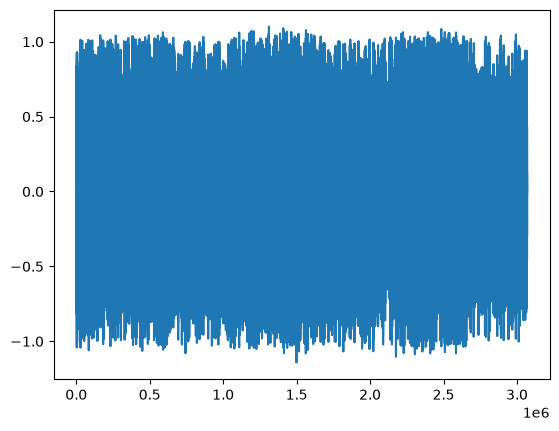

In [4]:
# opening up a random song (index 4)
y,sr = librosa.load(f"{TRACKS_DIR}/{fnames[4]}")

plt.plot(y)
plt.show()

display(Audio(y, rate=sr))

This is how we extract the center frequency and the lowest/highest frequencies of our signal, throughout the song.

Because these functions were written to work with multi-channel audio, they'll always return a list of lists. In our case, we just have a single channel, so our result will be at index $0$ of the returned list.

That's why we have `sc[0]`, `smin[0]`, `smax[0]` below.

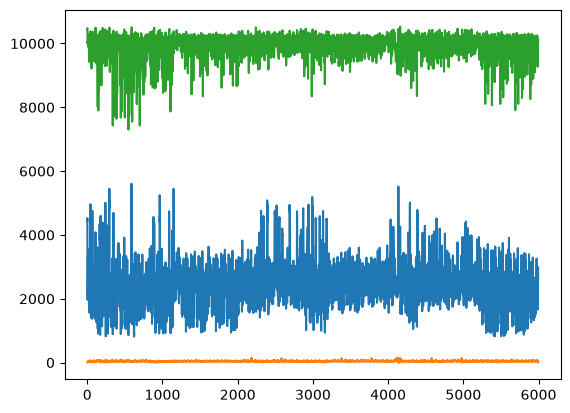

In [5]:
# average frequency
sc = librosa.feature.spectral_centroid(y=y)

# min and max frequencies
smin = librosa.feature.spectral_rolloff(y=y, roll_percent=0.01)
smax = librosa.feature.spectral_rolloff(y=y, roll_percent=0.99)

plt.plot(sc[0])
plt.plot(smin[0])
plt.plot(smax[0])
plt.show()

This is a start.

The functions give us multiple values because the avg/min/max frequency changes over time, but we can average the `spectral_centroid` and the two `spectral_rolloff` frequencies to get $3$ values that represent our entire audio file.

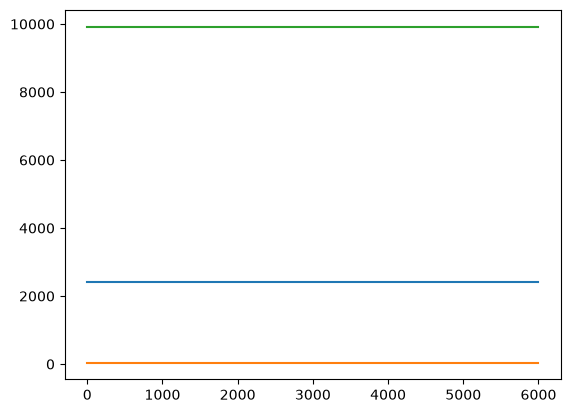

In [6]:
sc_val = sum(sc[0]) / len(sc[0])
smin_val = sum(smin[0]) / len(smin[0])
smax_val = sum(smax[0]) / len(smax[0])

plt.plot([0, len(sc[0])], [sc_val, sc_val])
plt.plot([0, len(smin[0])], [smin_val, smin_val])
plt.plot([0, len(smax[0])], [smax_val, smax_val])
plt.show()

Not bad.

### MFCCs

But, we can extend this idea with Mel-Frequency Cepstral Coefficients (MFCC). MFCCs are a compact, numerical representation of an audio signal's frequency characteristics, that divide an audio frequency range into bands based on human hearing sensitivities. So, instead of just $3$ frequencies, like we got above, the total frequency range is divided into $10$ to $20$ values that represent our audio signal.

And of course `librosa` has an `mfcc()` function:

(10, 5996)


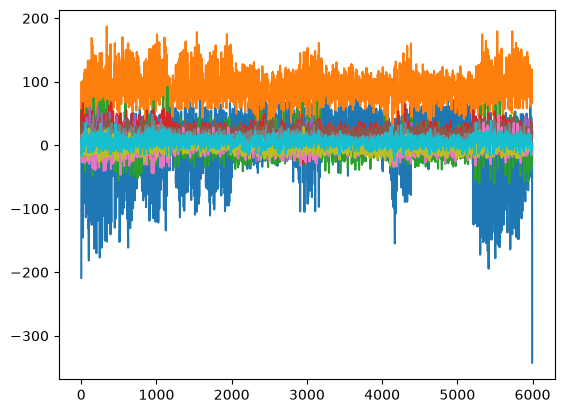

In [7]:
mfccs = librosa.feature.mfcc(y=y, n_mfcc=10)
print(mfccs.shape)

for vs in mfccs:
  plt.plot(vs)
plt.show()

### Average MFCCs

Like the `spectral_centroid()` function, the `mfcc()` function gives us multiple values for each frequency channel/band, since these change over time as the audio changes. We'll assume that one value per frequency band is enough and average them over time, so we end up with only $10$ numbers to represent our audio.

(10,)


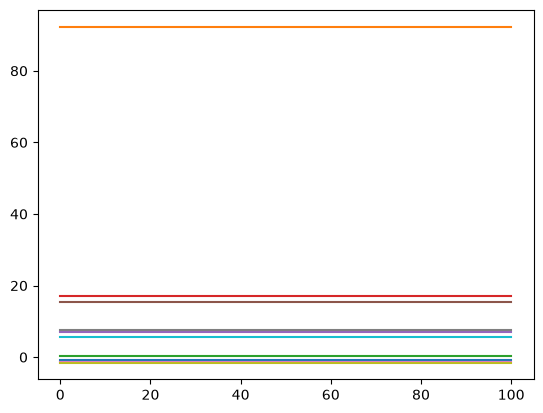

In [8]:
mfccs_avg = mfccs.mean(axis=1)
print(mfccs_avg.shape)

for vs in mfccs_avg:
  plt.plot([0,100], [vs, vs])
plt.show()

### Back to Shazam

This is what's behind the [Shazam algorithm](https://www.youtube.com/watch?v=b6xeOLjeKs0): a large database of songs, where each song is described with only a few features so they can be organized, searched, queried and compared very very quickly.

Another [video](https://www.youtube.com/watch?v=kMNSAhsyiDg) reference.

Let's implement something like this.

We'll focus on a single album, with about $30$ songs, but the same strategy (with minor modifications) will work for datasets of many more songs.

Here's the outline of what we have to do:

1. Extract MFCC features from all songs in our database (single album)
2. Create a dataset of song features
3. Given an input sound clip: extract its MFCC features
4. Find closest song in database by feature distance

In [ ]:
# Let's define a helper function that:
#   given a list of samples, 
#   returns a dictionary of extracted mfcc values.
#   to extract the mfcc values, repeat the steps done above:
#     - run mfcc extraction on samples
#     - average each mfcc array
#   the dictionary can have keys in whatever format (mfcc0, mfcc1, ... or feat0, feat1, ...), 
#   we just need named features for the DataFrame
#   check: if n_mfcc is 20, the resulting dict should have 20 keys/values

def get_features(y, n_mfcc=20):
  mfeats = {} 

  # extract mfccs--> one row per frequency band + one column per moment in time
  mfccs = librosa.feature.mfcc(y=y, n_mfcc=n_mfcc)

  # average each band over time--> get the n_mfcc numbers
  mfccs_avg = mfccs.mean(axis=1)

  # put them in a dictionary with named keys
  for i in range(len(mfccs_avg)):
    mfeats["mfcc" + str(i)] = float(mfccs_avg[i])

  return mfeats #bro i messed up with the indentation...

In [15]:
# check with the previous song
feats = get_features(y)
print(len(feats))    
print(feats)
print(len(get_features(y, n_mfcc=10)))   

20
{'mfcc0': -0.7474654316902161, 'mfcc1': 92.35462188720703, 'mfcc2': 0.19578416645526886, 'mfcc3': 16.9822998046875, 'mfcc4': 6.9186482429504395, 'mfcc5': 15.270938873291016, 'mfcc6': -1.317757248878479, 'mfcc7': 7.606240272521973, 'mfcc8': -1.5181429386138916, 'mfcc9': 5.708029270172119, 'mfcc10': 0.6714590191841125, 'mfcc11': 4.795195579528809, 'mfcc12': -1.870469331741333, 'mfcc13': 1.4114898443222046, 'mfcc14': -0.31112945079803467, 'mfcc15': 1.396399736404419, 'mfcc16': -1.2231796979904175, 'mfcc17': 3.015442371368408, 'mfcc18': -4.852982521057129, 'mfcc19': -0.3094211518764496}
10


isa thoughts-- is checking with 20 bands a good choice? should there be more? maybe in the context of this notebook yes, but there are definetely so many more... hmmmm

In [16]:
# TODO: run the get_features() function in one of the loaded files
feats = get_features(y)

# TODO: check the output and see if it makes sense
print(len(feats))  
for k in feats:
  print(k, round(feats[k], 2))

20
mfcc0 -0.75
mfcc1 92.35
mfcc2 0.2
mfcc3 16.98
mfcc4 6.92
mfcc5 15.27
mfcc6 -1.32
mfcc7 7.61
mfcc8 -1.52
mfcc9 5.71
mfcc10 0.67
mfcc11 4.8
mfcc12 -1.87
mfcc13 1.41
mfcc14 -0.31
mfcc15 1.4
mfcc16 -1.22
mfcc17 3.02
mfcc18 -4.85
mfcc19 -0.31


isa notes-- mfcc is close to -1 (the earlier averaged-MCC plot was about -0.75) so it is more or less good enough

### 1. Extract MFCC features from all songs

It takes about $20$ seconds to extract features for all songs.

In [17]:
# TODO: Run the function on all tracks and extract their average MFCCs

# TODO: iterate over the list of filenames, open each file,
#       extract mfcc features and append result to a list

track_feats = []

for fn in fnames:
  y, sr = librosa.load(f"{TRACKS_DIR}/{fn}")
  feats = get_features(y)
  track_feats.append(feats)

# should match...
print(len(track_feats), len(fnames))
print(track_feats[0])

34 34
{'mfcc0': -82.5860595703125, 'mfcc1': 79.53273010253906, 'mfcc2': 15.281947135925293, 'mfcc3': 29.399259567260742, 'mfcc4': 6.727076530456543, 'mfcc5': 11.497275352478027, 'mfcc6': -0.07376767694950104, 'mfcc7': 11.575368881225586, 'mfcc8': -3.0110397338867188, 'mfcc9': 10.090432167053223, 'mfcc10': -0.6602332592010498, 'mfcc11': 3.245026111602783, 'mfcc12': 1.0927023887634277, 'mfcc13': 1.200370192527771, 'mfcc14': -1.564979910850525, 'mfcc15': 3.8272948265075684, 'mfcc16': -3.1707165241241455, 'mfcc17': 1.2720928192138672, 'mfcc18': -2.1068079471588135, 'mfcc19': 1.5617727041244507}


### 2. Create `DataFrame` of song features

In [18]:
# TODO: put results in pandas DataFrame using the from_records() function
tracks_df = pd.DataFrame.from_records(track_feats)

print(tracks_df.shape)  
tracks_df.head()


(34, 20)


,mfcc0,mfcc1,mfcc2,mfcc3,mfcc4,mfcc5,mfcc6,mfcc7,mfcc8,mfcc9,mfcc10,mfcc11,mfcc12,mfcc13,mfcc14,mfcc15,mfcc16,mfcc17,mfcc18,mfcc19
0,-82.586060,79.532730,15.281947,29.399260,6.727077,11.497275,-0.073768,11.575369,-3.011040,10.090432,-0.660233,3.245026,1.092702,1.200370,-1.564980,3.827295,-3.170717,1.272093,-2.106808,1.561773
1,-36.498466,68.565880,1.131177,17.951372,5.481598,9.588413,-5.838254,0.816502,-4.664019,-0.872571,-5.979408,3.180954,-4.455261,0.461847,-0.487985,1.974657,-6.495473,-0.648695,-4.788703,-2.601770
2,-14.431624,91.889542,-17.692987,20.666237,2.245853,13.001684,-1.321214,9.948376,-0.615950,11.860087,1.530263,6.526819,-1.141762,4.144239,-2.058718,3.202840,-1.356414,2.854834,0.653201,3.837844
3,-62.079441,79.199989,5.043945,10.326107,14.655840,3.606573,-6.818017,7.708108,-0.689195,3.924184,-2.623504,3.656586,-4.205101,-3.083404,-3.361222,-0.709391,-5.950740,3.015170,-2.148083,-1.850845
4,-0.747465,92.354622,0.195784,16.982300,6.918648,15.270939,-1.317757,7.606240,-1.518143,5.708029,0.671459,4.795196,-1.870469,1.411490,-0.311129,1.396400,-1.223180,3.015442,-4.852983,-0.309421


In [19]:
# thinking about how to store the song names with the features
# use the filenames as the row labels
tracks_df.index = fnames

# keep them as a regular column
# tracks_df["name"] = fnames

# not super important at this moment, but possiblity later one will be better

### To Be Continued...

Now we have a dataset of extracted features for all songs in an album.

The idea is that if we repeat the mfcc extraction on a random song clip, we can use distance calculations to find the closest song to the clip.

The next step is to create a function that, given a set of mfcc features, finds the song in our dataset with the most similar features.

This is similar to one of the exercises in Homework02, where we found the closest cities to a given city; and similar to the MoMA exercise, where we found the closest apartment to a location.

The difference is that in those cases our distance was calculated using $2$ features (latitude and longitude), but now our distances will be calculated using $20$ features.

The math is the same. We'll continue next week, but in case you want to write down some notes or test out some stuff....

In [20]:
# TODO: implement a function that returns distances between 2 mfcc feature lists
def mfcc_dist(mfccA, mfccB):
  sum_of_squares = 0
  # TODO: iterate over pairs of features
  for a, b in zip(mfccA, mfccB): #zip from HW2 distance formula
    sum_of_squares += (a - b) ** 2 #sum of the square of their differences

  #       return the square root of that sum
  return sum_of_squares ** 0.5

In [ ]:
# testing
song0 = list(tracks_df.iloc[0])
song1 = list(tracks_df.iloc[1])

print(mfcc_dist(song0, song0))   
print(mfcc_dist(song0, song1))   
print(mfcc_dist(song1, song0))   

0.0
54.3711323513913
54.3711323513913


isa notes/thoughts-- will a short clip from the middle of a song average close to the song's whole average? I am thinking of songs that might have different "sections" throughout-- like bohemian rapsody or like-- a scene/sampled song that might be mistake for the original...

i am sure there is a way to categorize/narrow down specific features